# M09-4 | ORT 自己的 PTQ 工具 vs PT2E：同樣得到 QDQ ONNX，兩條路差在哪

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m09_onnx_runtime/04_ort_quant_compare.ipynb)

M09-1～M09-3 的 QDQ ONNX，除了 M09-3 的 OpZooNet，都是「先在 PyTorch 用 PT2E 量化，再匯出」。ORT 也有自己的 PTQ 工具，直接吃 fp32 ONNX、在 ONNX 圖上插 Q/DQ：

```text
PT2E 路線：PyTorch 模型 → PT2E → torch.onnx.export          QDQ ONNX
ORT 路線 ：PyTorch 模型 → torch.onnx.export → quantize_static  QDQ ONNX
```

- **A.** `quantize_static` 的預設設定，與它產生的圖。
- **B.** 精度：PT2E 的 QDQ ONNX vs ORT 工具的兩種設定。
- **C.** 同一個工具的另一種輸出：QOperator format。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m09_onnx_runtime")

In [1]:
import inspect

import onnxruntime as ort
import torch
from onnxruntime.quantization import QuantFormat, quantize_static

from common.pt2e import quiet  # 必須在 onnx／torchao 之前 import
from common.data import make_loader, trained_tiny_net
from common.env import env_summary
from common.graph_utils import sqnr
from common.models import example_inputs
from common.onnx_utils import onnx_op_counts, ort_quantize, ort_run, ort_session, to_onnx, xnnpack_qdq
from common.viz import draw_onnx, table

quiet()
_ = torch.manual_seed(0)
print(env_summary() + f"｜onnxruntime {ort.__version__}")

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True｜onnxruntime 1.30.0


兩邊的輸入（同 M09-1）：

- fp32 ONNX：`torch.onnx.export(fp32 模型, x, dynamo=True)`（`to_onnx`），是 `quantize_static` 的輸入。
- PT2E 的 QDQ ONNX：PT2E（`xnnpack_qdq`）的 Q/DQ 圖，再 `torch.onnx.export`。

兩邊用同一份校準資料（`common.data.calibration_batches`，128 筆）。

In [2]:
model = trained_tiny_net()
x = example_inputs()
fp32_onnx = to_onnx(model, x)
pt2e_onnx = to_onnx(xnnpack_qdq(model, x), x)

## A. `quantize_static` 的預設設定，與它產生的圖

`inspect.signature` 讀出 `quantize_static` 的預設值，和 PT2E 這邊（torchao 測試版 XNNPACKQuantizer）的設定對照：

In [3]:
params = inspect.signature(quantize_static).parameters
pt2e = {"quant_format": "QDQ（匯出就是 QDQ）", "activation_type": "int8 per-tensor affine",
        "weight_type": "int8 對稱 [-127, 127]", "per_channel": "True（xnnpack_qdq 傳 is_per_channel=True）",
        "calibrate_method": "HistogramObserver"}
table([[k, str(params[k].default), v] for k, v in pt2e.items()], ["參數", "ORT 預設", "PT2E（xnnpack_qdq）"])

參數,ORT 預設,PT2E（xnnpack_qdq）
quant_format,QDQ,QDQ（匯出就是 QDQ）
activation_type,QInt8,int8 per-tensor affine
weight_type,QInt8,"int8 對稱 [-127, 127]"
per_channel,False,True（xnnpack_qdq 傳 is_per_channel=True）
calibrate_method,CalibrationMethod.MinMax,HistogramObserver


ORT 的 activation 預設非對稱、weight 預設對稱，設定在 `extra_options` 的 `ActivationSymmetric`／`WeightSymmetric`。

`quantize_static(fp32 ONNX, 輸出路徑, 校準資料)` 全用預設值。本專案的 `ort_quantize` 包了三件事：

- 工具只能寫檔，所以輸出經過暫存檔再讀回。
- 工具會改動傳進去的 `ModelProto`（把 weight 改成指向暫存檔的 external data），同一個物件傳第二次就讀不到，所以每次傳一份 `copy.deepcopy`。
- 工具的警告走 Python 的 root logger，先收起來，回傳給呼叫端（C 段會印一則）。

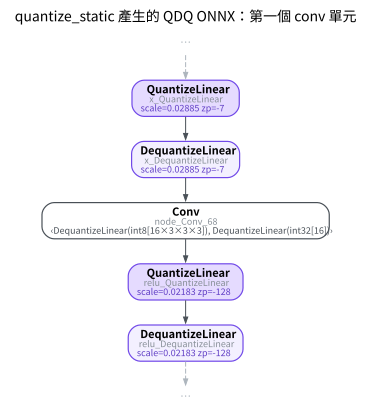

In [4]:
ort_default, _ = ort_quantize(fp32_onnx)
first_conv = next(n.name for n in ort_default.graph.node if n.op_type == "Conv")
draw_onnx(ort_default, focus=first_conv, hops=2, title="quantize_static 產生的 QDQ ONNX：第一個 conv 單元")

In [5]:
c_fp32, c_ort = onnx_op_counts(fp32_onnx), onnx_op_counts(ort_default)
print(f"Relu：fp32 ONNX {c_fp32.get('Relu', 0)} 個 → quantize_static 之後 {c_ort.get('Relu', 0)} 個")
assert c_fp32["Relu"] > 0 and c_ort.get("Relu", 0) == 0

Relu：fp32 ONNX 4 個 → quantize_static 之後 0 個


和 M09-1 A 段 PT2E 匯出的第一個 conv 單元比，有三處不同：

1. **沒有 Relu**：工具在量化時就把 conv 後面的 Relu 拿掉，改由後面 QuantizeLinear 的 zero point = -128 做 clamp。這是 M09-2 裡 ORT 在 EXTENDED 才做的事，這裡寫進了檔案。
2. **bias 已經是 `DequantizeLinear(int32[…])`**：M09-2 的 BASIC 才做的 bias 量化，這裡也寫進了檔案。
3. **weight 是 per-tensor**：預設 `per_channel=False`。

ORT 的工具只看得到 ONNX 圖，但做的決定和 PT2E 的 quantizer 同一類：哪條邊插 Q/DQ、scale 由校準資料算。

## B. 精度

四個 `.onnx` 都用 ORT 的 CPU EP（預設等級 `ORT_ENABLE_ALL`，`ort_session`）跑同一份 1024 筆測試資料（同 M05-1）：

In [6]:
ort_pc, _ = ort_quantize(fp32_onnx, per_channel=True)
candidates = {
    "fp32 ONNX": fp32_onnx,
    "PT2E → torch.onnx.export": pt2e_onnx,
    "quantize_static：預設（per-tensor weight）": ort_default,
    "quantize_static：per_channel=True": ort_pc,
}
xs, ys = zip(*make_loader(n=1024, seed=2, shuffle=False))
x_test, y_test = torch.cat(xs), torch.cat(ys)
with torch.no_grad():
    y_fp32 = model(x_test)
acc, snr = {}, {}
for name, m in candidates.items():
    out = ort_run(ort_session(m), x_test)
    acc[name], snr[name] = (out.argmax(1) == y_test).float().mean().item(), sqnr(y_fp32, out)
table([[name, "-" if name == "fp32 ONNX" else f"{snr[name]:.2f}", f"{acc[name]:.4f}"] for name in candidates],
      ["", "對 PyTorch fp32 的 SQNR (dB)", "accuracy"])

,對 PyTorch fp32 的 SQNR (dB),accuracy
fp32 ONNX,-,0.7109
PT2E → torch.onnx.export,29.18,0.7061
quantize_static：預設（per-tensor weight）,27.81,0.7129
quantize_static：per_channel=True,29.68,0.7109


In [7]:
quantized = list(candidates)[1:]
n_diff = round((max(acc[n] for n in quantized) - min(acc[n] for n in quantized)) * len(y_test))
print(f"三個量化版本的 accuracy 最多差 {n_diff} 筆（共 {len(y_test)} 筆）")
print(f"SQNR 最高：{max(quantized, key=lambda n: snr[n])}；最低：{min(quantized, key=lambda n: snr[n])}")
assert all(snr[n] > 20 for n in quantized)

三個量化版本的 accuracy 最多差 7 筆（共 1024 筆）
SQNR 最高：quantize_static：per_channel=True；最低：quantize_static：預設（per-tensor weight）


三個量化版本的 accuracy 只差幾筆，這麼小的差距分不出高下。兩條路的設定不同（activation 的 observer 是 Histogram 或 MinMax；weight 是 per-tensor 或 per-channel），SQNR 的差距來自哪一項，這裡沒有逐項拆開。

要點在流程而不是分數：兩條路的產物都是 QDQ ONNX，ORT 執行時用同一套 QDQ node fusion（M09-2）。

## C. QOperator format

`quantize_static` 還有另一種輸出格式：`quant_format=QuantFormat.QOperator`。

In [8]:
qop, warnings = ort_quantize(fp32_onnx, quant_format=QuantFormat.QOperator)
print("QOperator format 的 op：", dict(onnx_op_counts(qop)))
for w in warnings:
    if "QuantFormat" in w:  # 另外兩則建議先做 pre-processing，與本段無關
        print("quantize_static 印出的警告：", w.strip())

QOperator format 的 op： {'QuantizeLinear': 2, 'QLinearConv': 4, 'MaxPool': 2, 'com.microsoft.QLinearAdd': 1, 'DequantizeLinear': 2, 'ReduceMean': 1, 'Reshape': 1, 'com.microsoft.QGemm': 1}
quantize_static 印出的警告： Please use QuantFormat.QDQ for activation type QInt8 and weight type QInt8. Or it will lead to bad performance on x64.


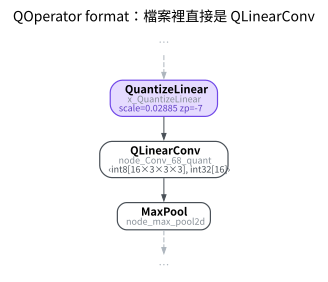

In [9]:
first_qconv = next(n.name for n in qop.graph.node if n.op_type == "QLinearConv")
draw_onnx(qop, focus=first_qconv, hops=1, title="QOperator format：檔案裡直接是 QLinearConv")

QOperator format 把融合好的 int8 op（`QLinearConv`、`QLinearAdd`…）直接寫進檔案，和 M09-2 裡 CPU EP 在 `ORT_ENABLE_EXTENDED` 改寫出來的圖幾乎一樣。ORT 的工具自己就印出警告，建議 int8 activation + int8 weight 用 QDQ format。

兩種格式的差別在「誰決定換成 int8 op」：

| 格式 | 誰決定換成 int8 op | 哪些 EP 能跑 |
|---|---|---|
| QDQ format | 執行時的 EP | 任何 EP（不認得就用 fp32 跑） |
| QOperator format | 量化工具 | 只有實作了這些 int8 op 的 EP |

「哪些 EP 能跑」這個 column 是 ORT 文件的說法，這裡只驗證了 CPU EP。PT2E 匯出的一定是 QDQ format。

## 小結

- ORT 的 `quantize_static` 和 PT2E 做同一件事：決定哪裡插 Q/DQ，用校準資料算 scale。只是它在 ONNX 圖上做。
- 它會順便把 Relu 併掉、把 bias 量化成 int32 寫進檔案；PT2E 把這些留給後端（M08 的 XNNPACK、M09-2 的 ORT）。
- QDQ format 留給 EP 在執行時決定；QOperator format 在量化時就把 int8 op 寫死。